In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np

#### Goals:
1. How many people do we have, and how many are victimized in each group?
2. Do people who enroll on time *look different* from people who don't (before we adjust for anything)?
3. Does victimization differ across covariates, and does that differ by enrollment group?

**Why do (2) at all?** In causal inference, the problem is that the two groups differ in ways that may also affect victimization (family wealth, test scores, prior arrests...). Those differences are called **confounders**. The models notebook adjusts for them.

#### Note:
1. currently drop rows where either timely_college or Y is missing (FUTURE STEPS: handle missing Y)
2. earliest arrest date makes unkown date (like -4) -> 0 (FUTURE STEPS: consider what we want to do with missing data)

#### How missingness is dealt with (currently):

1. missing treatment (0?) or outcome (455) - exclude the respondent (drop NA)
2. missing categorical covariate - keep a separate category for the missing response code
3. missing continuous covariate - fill with the median and add a missingness indicator
4. ungraded parental schooling - fill the numerical education value with the median and add an ungraded indicator 

In [3]:
df = pd.read_csv("/Users/nicoletimko/Desktop/cmu_year3/capstone_victimization/full_dataset/data_with_Y_18.csv")

# drop rows where either treatment or outcome is missing
df = df.dropna(subset=["timely_college", "Y"]).copy() # missing treatment or outcome

# ensure treatment and outcome are integers 0/1
df["timely_college"] = df["timely_college"].astype(int) 
df["Y"] = df["Y"].astype(int)   

# readable labels for plots
df["enrollment"] = df["timely_college"].map({0: "No timely enrollment", 1: "Timely enrollment"})  # readable labels for plots

#### New covariate: earliest arrest date -> arrested_before_18

In [4]:
# ---- New covariate: arrested before age 18 ----
date = df["earliest_arrest_date"]

arrest_year = date // 100
arrest_month = date % 100

# Calculate age only when arrest date and birth information are valid.
valid = (
    date.gt(0)
    & arrest_month.between(1, 12)
    & df["birth_year"].gt(0)
    & df["birth_month"].between(1, 12)
)

arrest_age = (
    arrest_year - df["birth_year"]
    + (arrest_month - df["birth_month"]) / 12
)

# Preserve negative survey codes.
# Leave blanks and rows with insufficient information as NaN.
df["arrested_before_18"] = date.where(date < 0, np.nan)

# Replace valid dates with:
# 1 = arrested before 18
# 0 = first arrested at 18 or older
df.loc[valid, "arrested_before_18"] = (
    arrest_age.loc[valid] < 18
).astype(int)

#### list of covariates

In [5]:
# "Categorical" = the numbers are group codes (1 = agree, 2 = disagree...), not amounts
categorical = [
    "teachers_good", "discipline_is_fair_agree_disagree", "percent_of_peers_who_smoke",
    "percent_of_peers_who_get_drunk_1_times_a_month", "percent_of_peers_belong_to_a_gang",
    "percent_of_peers_who_have_had_sex", "bullying_victim_before_age_12", "sex",
    "r_ever_live_through_hard_times", "race_ethnicity",
    "r_victim_of_bullying_12_18_years", "mother_serve_prison_sentence",
    "father_serve_prison_sentence", "lived_with_both_bio_parents_at_birth", "arrested_before_18",
]
# "Continuous" = real amounts or counts (dollars, days, years of school...)
continuous = [
    "total_number_of_incarcerations", "r_threatened_to_be_hurt_at_school", "r_in_a_fight_at_school",
    "days_r_absent_from_school", "percent_chance_r_victim_of_violent_crime_by_next_year",
    "household_net_worth", "household_size", "biological_father_education",
    "biological_mother_education", "asvab_math_verbal_score_percent",
]

#### cleaning survey codes

This survey uses negative numbers as codes: -1 refused, -2 don't know, -3 invalid skip, -4 question not asked (skipped), -5 didn't do the interview. They are NOT real values.

1. Categorical variables: turn each value into text and keep the codes as their own group.
2. Continuous variables: a code is not a real amount, so blank it out, remember who was blank, then fill with the median.

FUTURE WORK: what to do with 95 in mother/father education (should be categorical insteaf of continuous)

In [6]:
codes = [-1, -2, -3, -4, -5]                            # the list of special codes

# Categorical variables: turn each value into text and keep the codes as their own group.
# Example: "-4" becomes its own category meaning "question not asked". This way we do NOT throw those people away.
for col in categorical:       # missing categorical covariates                    
    df[col] = df[col].fillna(-9).astype(int).astype(str)    # make missing categorical responses their own categories or fill true blanks with -9

# Continuous variables: a code is not a real amount, so blank it out, remember who was blank, then fill with the median.

# 95 means "ungraded", not 95 years of school. There is a separate 0 years of school, so make 95 NA and impute with median (CHANGE)
for col in ["biological_father_education", "biological_mother_education"]:
    # Record ungraded schooling separately.
    df[col + "_ungraded"] = (df[col] == 95).astype(int)

    # Blank out 95 so it isn't treated as 95 years.
    df[col] = df[col].replace(95, np.nan)

for col in continuous:                                  # go through each continuous column
    df[col] = df[col].mask(df[col].isin(codes))         # replace the special codes with "missing" (NaN)
    df[col + "_missing"] = df[col].isna().astype(int)   # new 0/1 column: 1 if this person's value was missing
    df[col] = df[col].fillna(df[col].median())          # fill missing values with the middle value (median) of everyone else

continuous_flags = [c + "_missing" for c in continuous] # names of the new "was missing" columns

#### sample size and raw difference between timely enrolled and not timely enrolled victims

In [7]:
print("People in analysis:", len(df))                                   # how many rows we kept

summary = df.groupby("enrollment")["Y"].agg(["size", "sum", "mean"])        # for each group: number of people, number victimized, victimization rate
summary.columns = ["people (size)", "victimized (sum)", "rate (mean)"]                          # friendlier column names
print(summary)                                                              # show the table

diff = summary.loc["Timely enrollment", "rate (mean)"] - summary.loc["No timely enrollment", "rate (mean)"]   # raw difference in rates (timely minus not timely)
print(f"\nRaw difference in victimization rate: {100 * diff:.2f} percentage points")           # show it in percentage points

People in analysis: 8467
                      people (size)  victimized (sum)  rate (mean)
enrollment                                                        
No timely enrollment           4014               257     0.064026
Timely enrollment              4453               263     0.059061

Raw difference in victimization rate: -0.50 percentage points


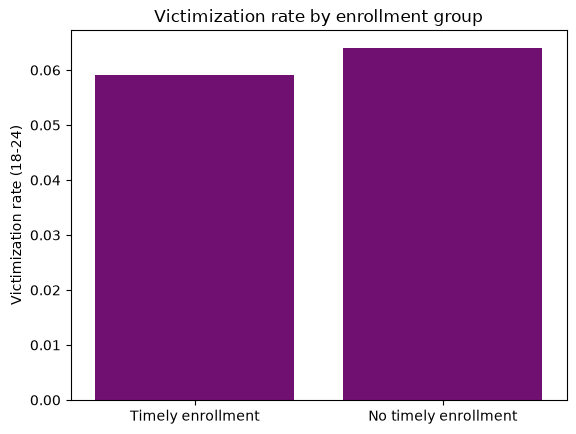

In [8]:
ax = sns.barplot(data=df, x="enrollment", y="Y", color="purple", errorbar=None) 
ax.set(xlabel="", ylabel="Victimization rate (18-24)", title="Victimization rate by enrollment group")  # axis labels and title
plt.show()                                                                  # display the plot

#### how many survey answers are special codes?

Before cleaning, many variables are mostly `-4` ("question not asked"). That is why dropping every row with a missing value leaves almost nobody

TODO!


#### do the two groups look different?

In [9]:
# Average of each continuous covariate in each enrollment group
group_means = df.groupby("enrollment")[continuous].mean().T      # rows = covariates, columns = groups
group_means["difference"] = group_means["Timely enrollment"] - group_means["No timely enrollment"]   # gap between groups
print(group_means.round(2).to_string())                          # show the table

enrollment                                             No timely enrollment  Timely enrollment  difference
total_number_of_incarcerations                                         0.39               0.06       -0.33
r_threatened_to_be_hurt_at_school                                      1.27               0.69       -0.58
r_in_a_fight_at_school                                                 0.62               0.20       -0.41
days_r_absent_from_school                                              6.16               3.60       -2.56
percent_chance_r_victim_of_violent_crime_by_next_year                  9.42               8.09       -1.33
household_net_worth                                                44713.48          102092.26    57378.78
household_size                                                         4.70               4.43       -0.26
biological_father_education                                           11.53              13.25        1.71
biological_mother_education          

In [10]:
# For the categorical covariates, show the % of each group in each category (a few important ones)
for col in categorical:   # loop over these variables
    table = pd.crosstab(df[col], df["enrollment"], normalize="columns") * 100                   # % of each group in each category
    print(f"\n{col} (percent of each group)")                                                   # title for this table
    print(table.round(1).to_string())                                                           # show it


teachers_good (percent of each group)
enrollment     No timely enrollment  Timely enrollment
teachers_good                                         
-1                              0.0                0.0
-2                              0.0                0.0
-4                              0.1                0.2
1                              13.8               20.9
2                              66.8               70.9
3                              15.2                6.6
4                               4.1                1.3

discipline_is_fair_agree_disagree (percent of each group)
enrollment                         No timely enrollment  Timely enrollment
discipline_is_fair_agree_disagree                                         
-1                                                  0.0                0.0
-2                                                  0.2                0.3
-4                                                  0.1                0.2
1                               

#### victimization rate by covariate, split by enrollment group

In [11]:
# from matplotlib.ticker import PercentFormatter

# ncols = 2
# nrows = (len(categorical) + ncols - 1) // ncols

# fig, axes = plt.subplots(
#     nrows, ncols,
#     figsize=(14, 4.5 * nrows),
#     squeeze=False,
# )

# groups = ["No timely enrollment", "Timely enrollment"]
# colors = {
#     "No timely enrollment": "mediumpurple",
#     "Timely enrollment": "teal",
# }

# for ax, col in zip(axes.flat, categorical):
#     category_order = sorted(df[col].unique(), key=float)
#     x = np.arange(len(category_order))
#     width = 0.4

#     counts = (
#         df.groupby([col, "enrollment"], observed=True)["Y"]
#         .agg(["sum", "size"])
#     )

#     for j, group in enumerate(groups):
#         positions = x + (j - 0.5) * width
#         rates = []
#         labels = []

#         for category in category_order:
#             if (category, group) in counts.index:
#                 row = counts.loc[(category, group)]
#                 victimized = int(row["sum"])
#                 people = int(row["size"])

#                 rates.append(victimized / people)
#                 labels.append(f"{victimized:,}/{people:,}")
#             else:
#                 rates.append(0)
#                 labels.append("0")

#         bars = ax.bar(
#             positions,
#             rates,
#             width=width,
#             color=colors[group],
#             label=group,
#         )

#         for bar, label in zip(bars, labels):
#             ax.annotate(
#                 label,
#                 xy=(
#                     bar.get_x() + bar.get_width() / 2,
#                     bar.get_height(),
#                 ),
#                 xytext=(0, 4),
#                 textcoords="offset points",
#                 ha="center",
#                 va="bottom",
#                 fontsize=8,
#                 rotation=90,
#             )

#     ax.set_xticks(x)
#     ax.set_xticklabels(category_order)

#     ax.set(
#         xlabel="",
#         ylabel="Victimization rate (18–24)",
#         title=col.replace("_", " ").capitalize(),
#     )
#     ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

#     top = ax.get_ylim()[1]
#     ax.set_ylim(0, max(top * 1.35, 0.05))
#     ax.legend(title="", fontsize=8, loc="upper left")

# for ax in list(axes.flat)[len(categorical):]:
#     ax.set_visible(False)

# plt.tight_layout()
# plt.show()

In [12]:
AGREE_4 = {1: "Strongly agree", 2: "Agree", 3: "Disagree", 4: "Strongly disagree"}

PEERS_5 = {
    1: "Almost none (less than 10%)",
    2: "About 25%",
    3: "About half (50%)",
    4: "About 75%",
    5: "Almost all (more than 90%)",
}

YES_NO = {0: "No", 1: "Yes"}

PARENT_EDU = {
    0: "None",
    1: "1st grade", 2: "2nd grade", 3: "3rd grade", 4: "4th grade", 5: "5th grade",
    6: "6th grade", 7: "7th grade", 8: "8th grade", 9: "9th grade", 10: "10th grade",
    11: "11th grade", 12: "12th grade",
    13: "1st year college", 14: "2nd year college", 15: "3rd year college",
    16: "4th year college", 17: "5th year college", 18: "6th year college",
    19: "7th year college", 20: "8th year college or more",
    95: "Ungraded",
}

CATEGORY_LABELS = {
    "teachers_good": AGREE_4,
    "discipline_is_fair_agree_disagree": AGREE_4,
    "percent_of_peers_who_smoke": PEERS_5,
    "percent_of_peers_who_get_drunk_1_times_a_month": PEERS_5,
    "percent_of_peers_belong_to_a_gang": PEERS_5,
    "percent_of_peers_who_have_had_sex": PEERS_5,
    "bullying_victim_before_age_12": YES_NO,
    "r_victim_of_bullying_12_18_years": YES_NO,
    "earliest_arrest_before_18": YES_NO,          # derived column; assumed 0/1
    "sex": {1: "Male", 2: "Female"},
    "r_ever_live_through_hard_times": YES_NO,
    "biological_father_education": PARENT_EDU,
    "biological_mother_education": PARENT_EDU,
    "mother_serve_prison_sentence": YES_NO,
    "father_serve_prison_sentence": YES_NO,
}

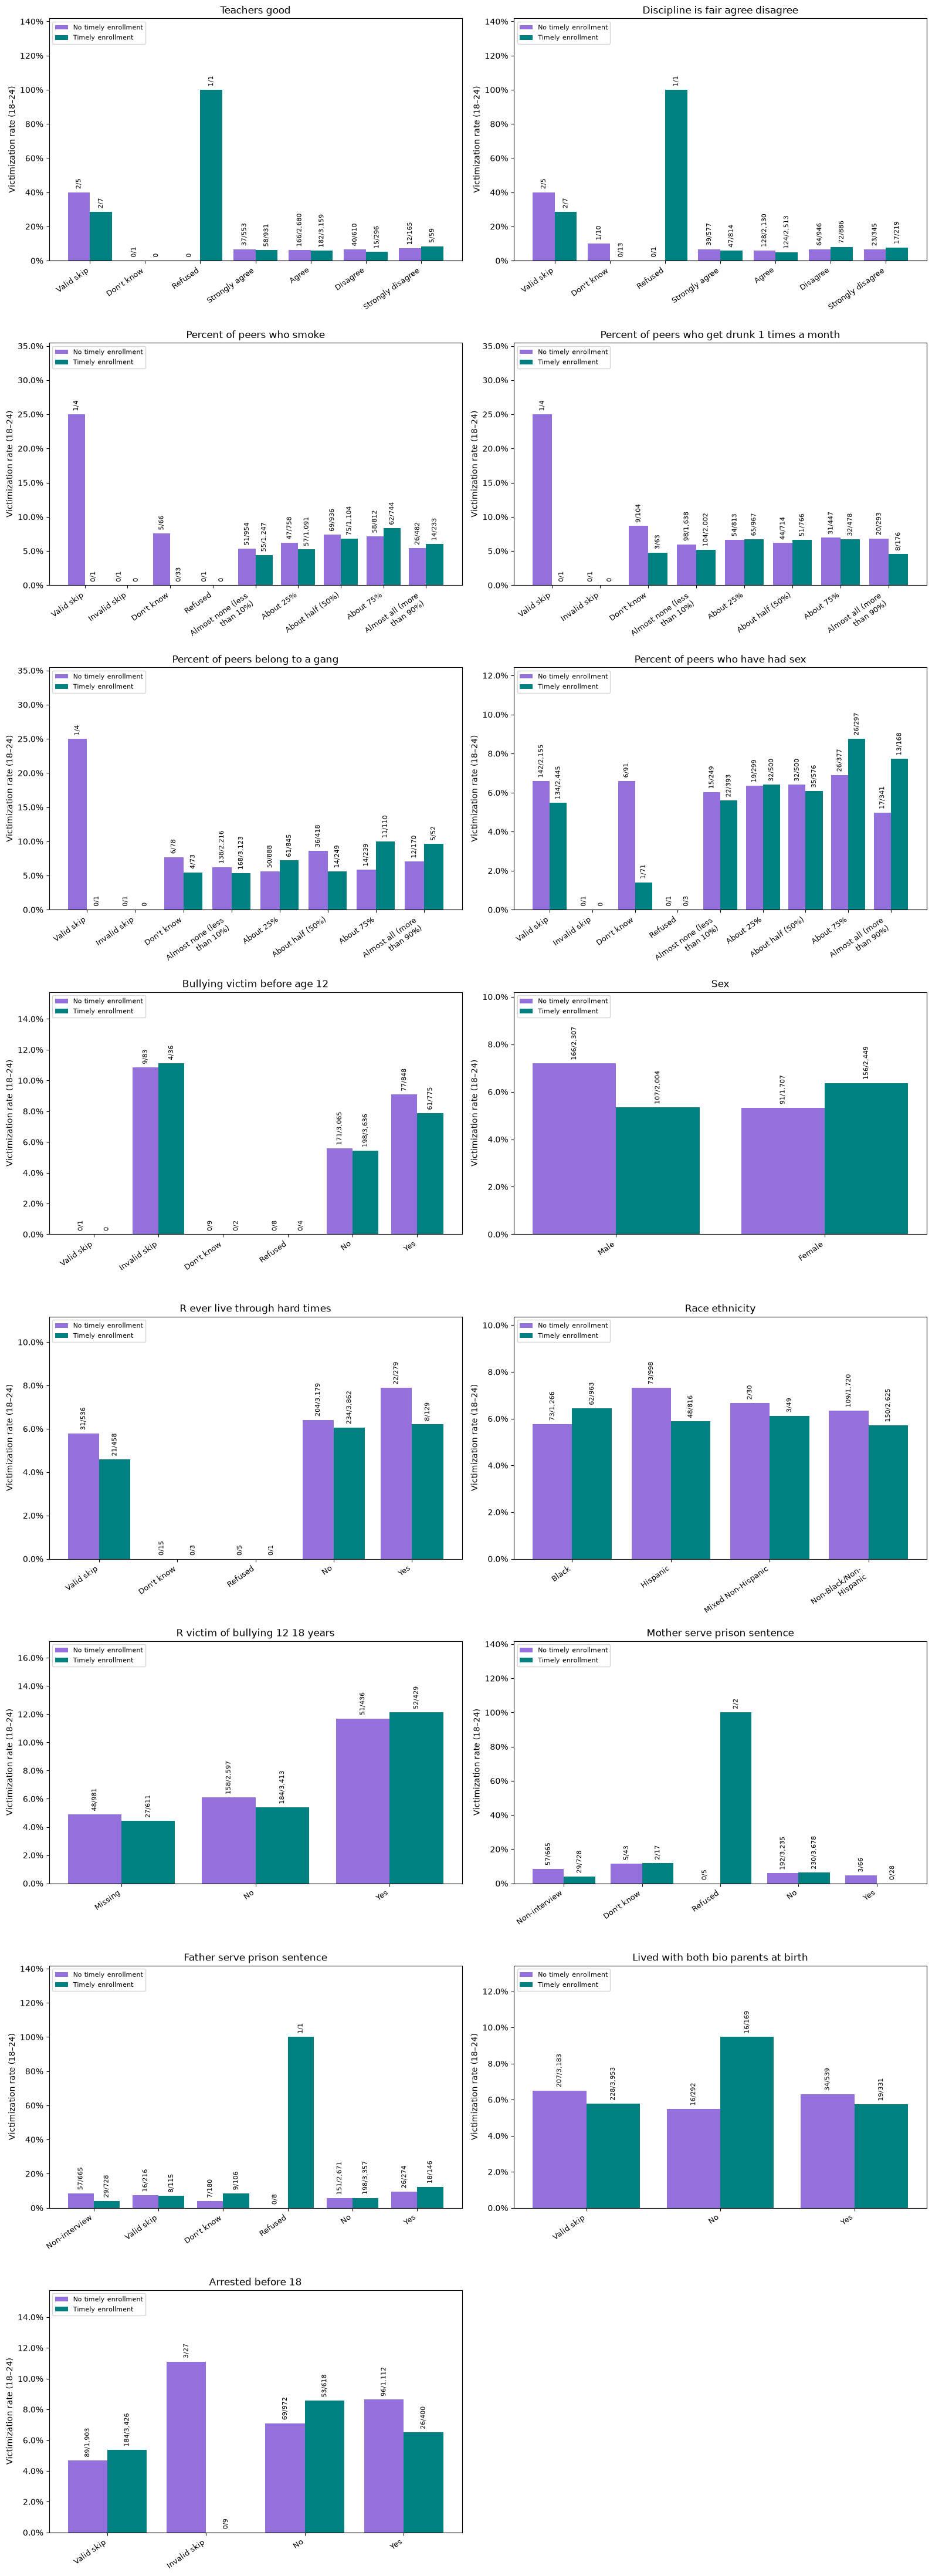

In [13]:
from matplotlib.ticker import PercentFormatter
import textwrap

# Match the actual column names in your data.
CATEGORY_LABELS["arrested_before_18"] = YES_NO
CATEGORY_LABELS["lived_with_both_bio_parents_at_birth"] = YES_NO

# Used only if race_ethnicity still contains numerical codes.
CATEGORY_LABELS["race_ethnicity"] = {
    1: "Black",
    2: "Hispanic",
    3: "Mixed Non-Hispanic",
    4: "Non-Black/Non-Hispanic",
}

MISSING_LABELS = {
    -1: "Refused",
    -2: "Don't know",
    -3: "Invalid skip",
    -4: "Valid skip",
    -5: "Non-interview",
    -9: "Missing",
}


def category_sort_key(value):
    """Sort numerical codes numerically; text categories alphabetically."""
    try:
        return (0, float(value))
    except (TypeError, ValueError):
        return (1, str(value))


def category_label(col, value):
    """Convert a code to its label, preserving unmapped text."""
    try:
        number = float(value)
        if not number.is_integer():
            return str(value)
        code = int(number)
    except (TypeError, ValueError):
        return str(value)

    if code in MISSING_LABELS:
        return MISSING_LABELS[code]

    return CATEGORY_LABELS.get(col, {}).get(code, str(value))


ncols = 2
nrows = (len(categorical) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 5.5 * nrows),
    squeeze=False,
)

groups = ["No timely enrollment", "Timely enrollment"]
colors = {
    "No timely enrollment": "mediumpurple",
    "Timely enrollment": "teal",
}

for ax, col in zip(axes.flat, categorical):
    category_order = sorted(
        df[col].dropna().unique(),
        key=category_sort_key,
    )

    x = np.arange(len(category_order))
    width = 0.4

    counts = (
        df.groupby([col, "enrollment"], observed=True)["Y"]
        .agg(["sum", "size"])
    )

    for j, group in enumerate(groups):
        positions = x + (j - 0.5) * width
        rates = []
        labels = []

        for category in category_order:
            if (category, group) in counts.index:
                row = counts.loc[(category, group)]
                victimized = int(row["sum"])
                people = int(row["size"])

                rates.append(victimized / people)
                labels.append(f"{victimized:,}/{people:,}")
            else:
                rates.append(0)
                labels.append("0")

        bars = ax.bar(
            positions,
            rates,
            width=width,
            color=colors[group],
            label=group,
        )

        for bar, label in zip(bars, labels):
            ax.annotate(
                label,
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height(),
                ),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                rotation=90,
            )

    # Replace codes with readable labels and wrap long labels.
    tick_labels = [
        textwrap.fill(category_label(col, category), width=18)
        for category in category_order
    ]

    ax.set_xticks(x)
    ax.set_xticklabels(
        tick_labels,
        rotation=35,
        ha="right",
        fontsize=9,
    )

    ax.set(
        xlabel="",
        ylabel="Victimization rate (18–24)",
        title=col.replace("_", " ").capitalize(),
    )
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

    top = ax.get_ylim()[1]
    ax.set_ylim(0, max(top * 1.35, 0.05))
    ax.legend(title="", fontsize=8, loc="upper left")

for ax in list(axes.flat)[len(categorical):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [14]:
# Continuous covariates: split people into 4 equal-sized groups (quartiles) and show the victimization rate in each
for col in continuous:                                            # loop over continuous covariates
    bins = pd.qcut(df[col], q=4, duplicates="drop")               # cut into up to 4 equal-sized groups (duplicates="drop" handles columns with many repeated values)
    t = df.groupby([bins, "enrollment"], observed=True)["Y"].agg(["size", "mean"])   # n and rate per group
    t.columns = ["n", "rate"]                                     # rename columns
    print(f"\n--- {col} ---")                                    # heading
    print(t.round(3).to_string())                                 # show the table


--- total_number_of_incarcerations ---
                                                        n   rate
total_number_of_incarcerations enrollment                       
(-0.001, 11.0]                 No timely enrollment  4014  0.064
                               Timely enrollment     4453  0.059

--- r_threatened_to_be_hurt_at_school ---
                                                           n   rate
r_threatened_to_be_hurt_at_school enrollment                       
(-0.001, 99.0]                    No timely enrollment  4014  0.064
                                  Timely enrollment     4453  0.059

--- r_in_a_fight_at_school ---
                                                n   rate
r_in_a_fight_at_school enrollment                       
(-0.001, 50.0]         No timely enrollment  4014  0.064
                       Timely enrollment     4453  0.059

--- days_r_absent_from_school ---
                                                   n   rate
days_r_absent_from_school enro

In [15]:
# ncols = 2
# nrows = (len(continuous) + ncols - 1) // ncols

# fig, axes = plt.subplots(
#     nrows, ncols,
#     figsize=(14, 4.5 * nrows),
#     squeeze=False,
# )

# groups = ["No timely enrollment", "Timely enrollment"]
# colors = {
#     "No timely enrollment": "mediumpurple",
#     "Timely enrollment": "teal",
# }

# for ax, col in zip(axes.flat, continuous):
#     # Exclude median-imputed values.
#     plot_df = df.loc[
#         df[col + "_missing"] == 0,
#         [col, "Y", "enrollment"]
#     ].dropna()

#     sns.boxplot(
#         data=plot_df,
#         x="Y",
#         y=col,
#         hue="enrollment",
#         order=[0, 1],
#         hue_order=groups,
#         palette=colors,
#         ax=ax,
#     )

#     ax.set_xticks([0, 1])
#     ax.set_xticklabels(["Not victimized", "Victimized"])
#     ax.set(
#         xlabel="Victimization (18–24)",
#         ylabel=col.replace("_", " ").capitalize(),
#         title=col.replace("_", " ").capitalize(),
#     )
#     ax.legend(title="", fontsize=8)

# for ax in list(axes.flat)[len(continuous):]:
#     ax.set_visible(False)

# plt.tight_layout()
# plt.show()

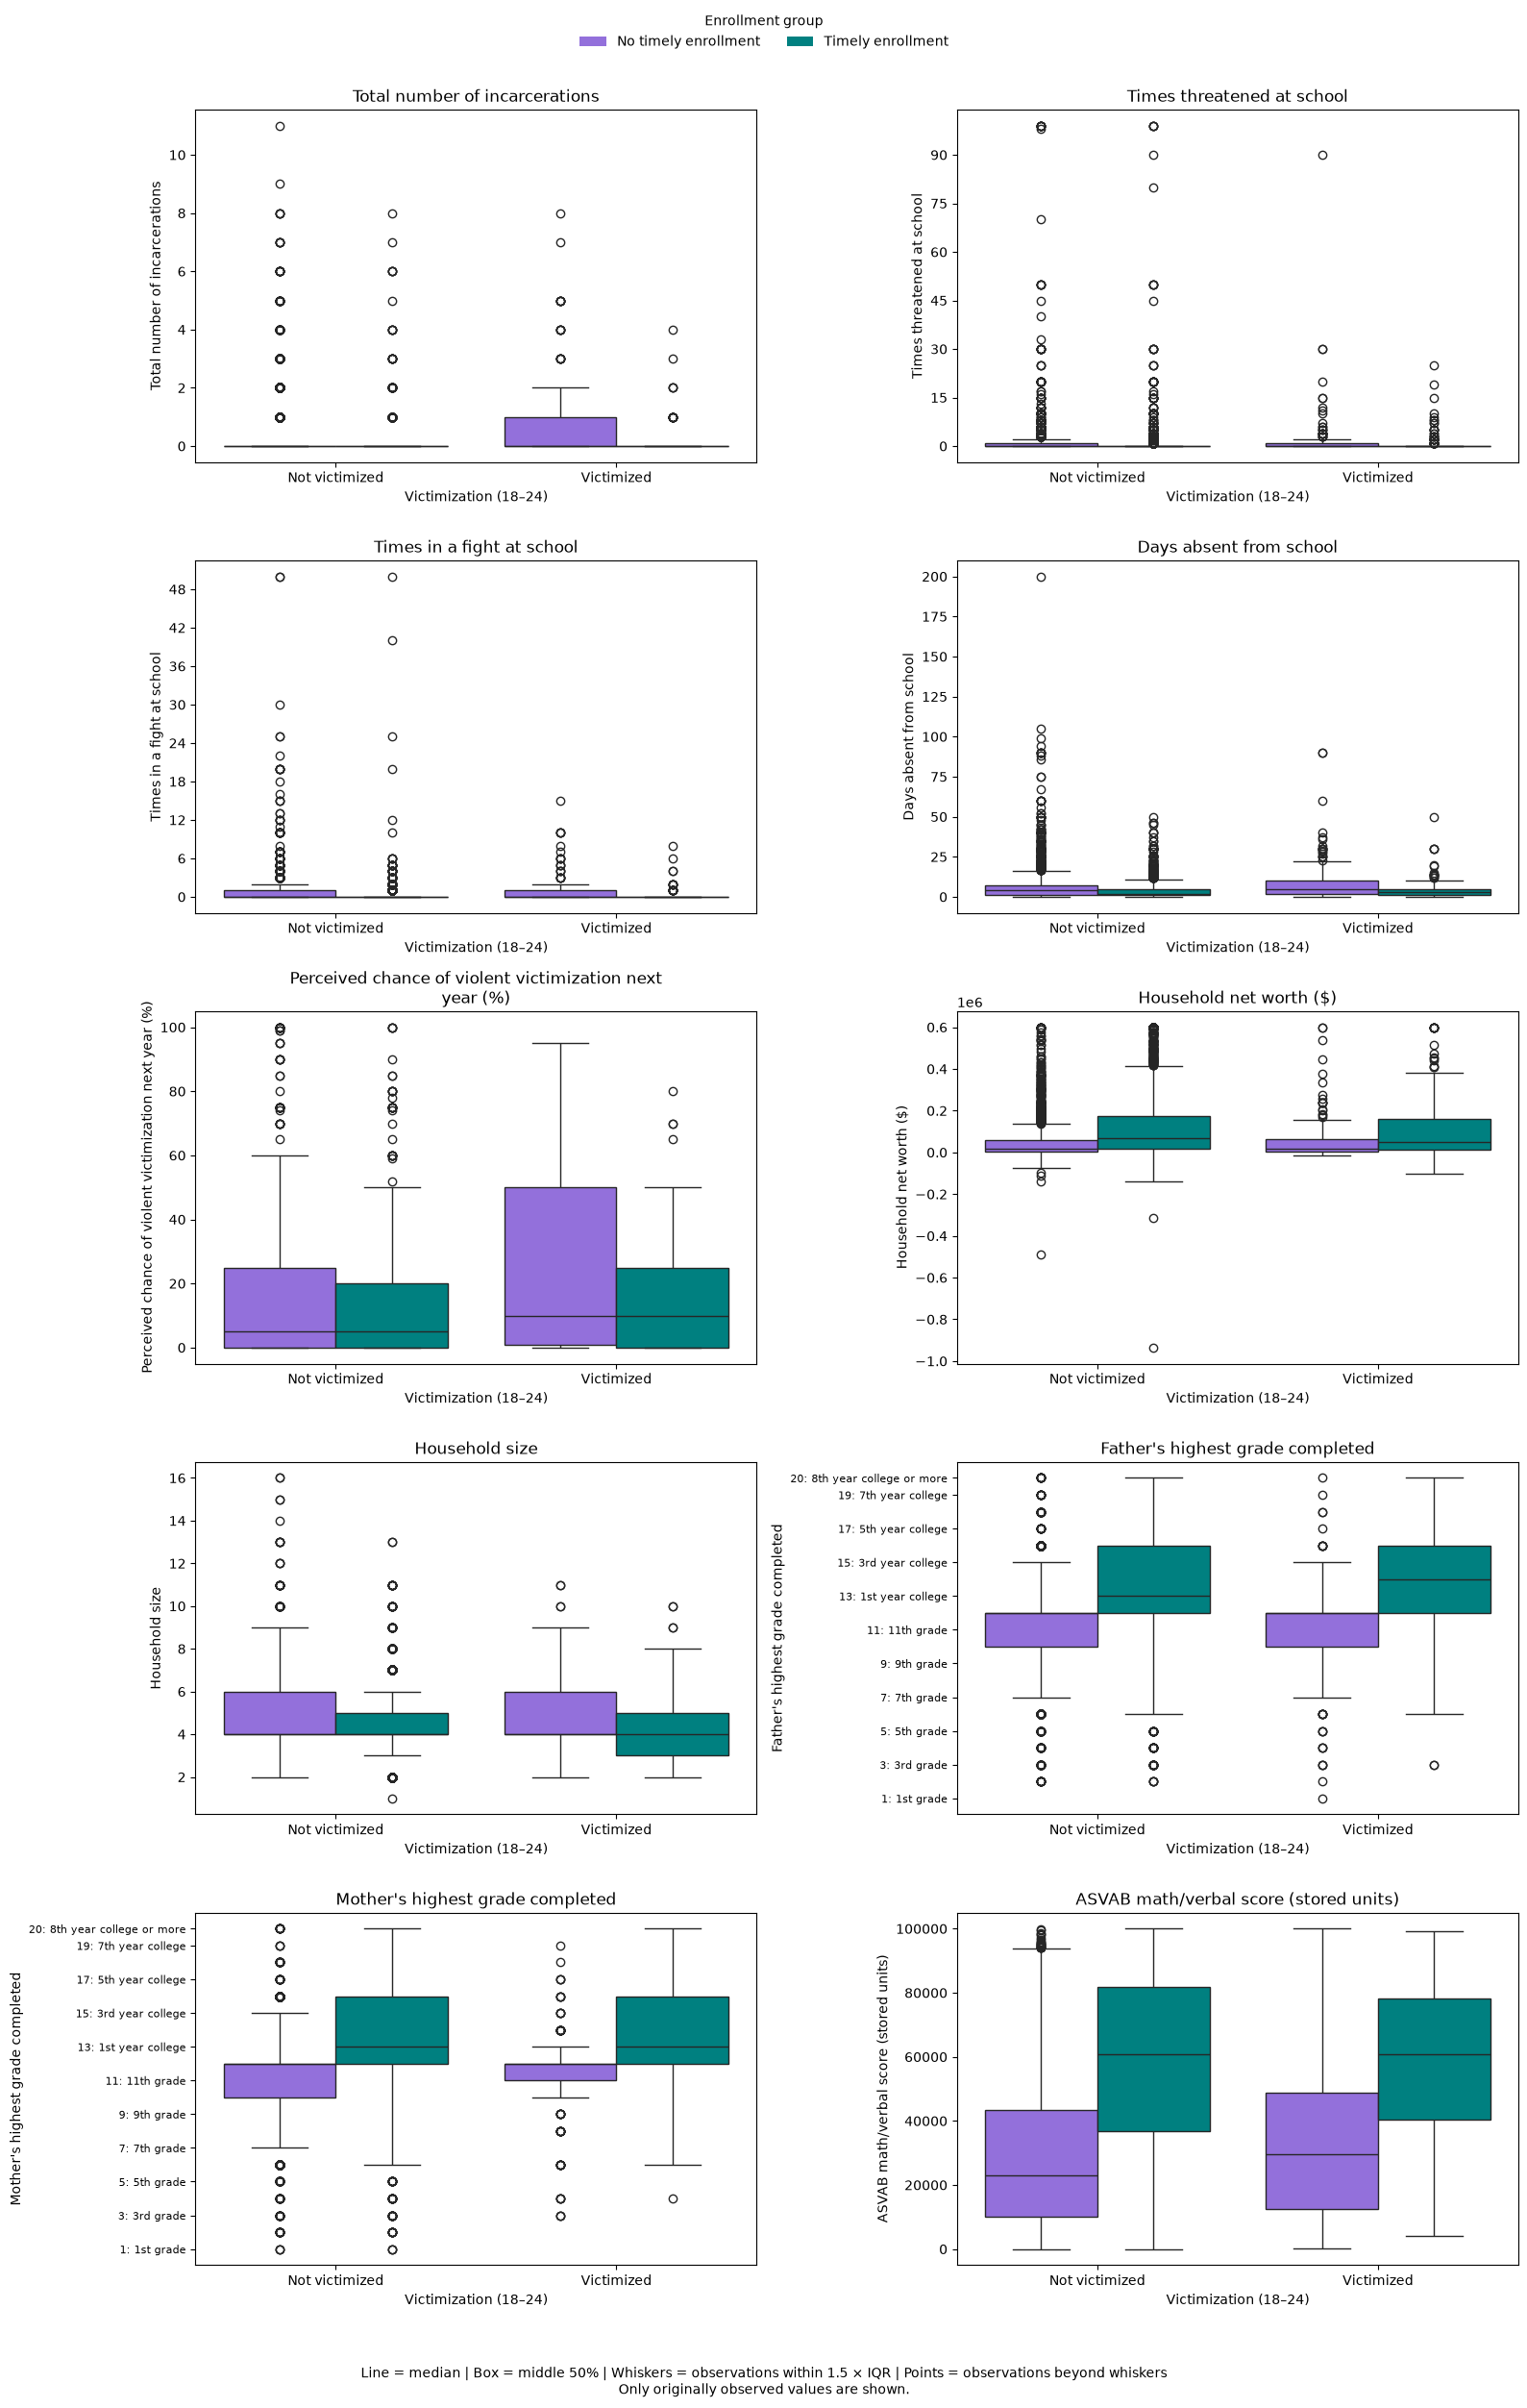

In [16]:
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
import textwrap

DISPLAY_NAMES = {
    "total_number_of_incarcerations": "Total number of incarcerations",
    "r_threatened_to_be_hurt_at_school": "Times threatened at school",
    "r_in_a_fight_at_school": "Times in a fight at school",
    "days_r_absent_from_school": "Days absent from school",
    "percent_chance_r_victim_of_violent_crime_by_next_year":
        "Perceived chance of violent victimization next year (%)",
    "household_net_worth": "Household net worth ($)",
    "household_size": "Household size",
    "biological_father_education": "Father's highest grade completed",
    "biological_mother_education": "Mother's highest grade completed",
    "asvab_math_verbal_score_percent": "ASVAB math/verbal score (stored units)",
}

education_columns = [
    "biological_father_education",
    "biological_mother_education",
]

ncols = 2
nrows = (len(continuous) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 5 * nrows),
    squeeze=False,
)

groups = ["No timely enrollment", "Timely enrollment"]
colors = {
    "No timely enrollment": "mediumpurple",
    "Timely enrollment": "teal",
}

for ax, col in zip(axes.flat, continuous):
    # Exclude median-imputed values.
    plot_df = df.loc[
        df[col + "_missing"] == 0,
        [col, "Y", "enrollment"]
    ].dropna()

    sns.boxplot(
        data=plot_df,
        x="Y",
        y=col,
        hue="enrollment",
        order=[0, 1],
        hue_order=groups,
        palette=colors,
        saturation=1,
        ax=ax,
    )

    # Remove individual legends; use one shared legend below.
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Not victimized", "Victimized"])

    name = DISPLAY_NAMES.get(col, col.replace("_", " ").capitalize())

    ax.set(
        xlabel="Victimization (18–24)",
        ylabel=name,
        title=textwrap.fill(name, width=48),
    )

    # Label education at the actual numerical grade positions.
    if col in education_columns and not plot_df.empty:
        lowest = max(0, int(np.floor(plot_df[col].min())))
        highest = min(20, int(np.ceil(plot_df[col].max())))

        # Every other grade keeps the axis readable.
        ticks = list(range(lowest, highest + 1, 2))
        if highest not in ticks:
            ticks.append(highest)

        ax.set_yticks(ticks)
        ax.set_yticklabels([
            f"{grade}: {PARENT_EDU.get(grade, str(grade))}"
            for grade in ticks
        ], fontsize=8)

    # Counts and household sizes are measured in whole numbers.
    elif col in [
        "total_number_of_incarcerations",
        "r_threatened_to_be_hurt_at_school",
        "r_in_a_fight_at_school",
        "days_r_absent_from_school",
        "household_size",
    ]:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))

for ax in list(axes.flat)[len(continuous):]:
    ax.set_visible(False)

# One enrollment legend for the whole figure.
handles = [
    Patch(facecolor=colors[group], label=group)
    for group in groups
]

fig.legend(
    handles=handles,
    title="Enrollment group",
    loc="upper center",
    bbox_to_anchor=(0.5, 1),
    ncol=2,
    frameon=False,
)

fig.text(
    0.5,
    0.005,
    "Line = median | Box = middle 50% | "
    "Whiskers = observations within 1.5 × IQR | "
    "Points = observations beyond whiskers\n"
    "Only originally observed values are shown.",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.035, 1, 0.97])
plt.show()

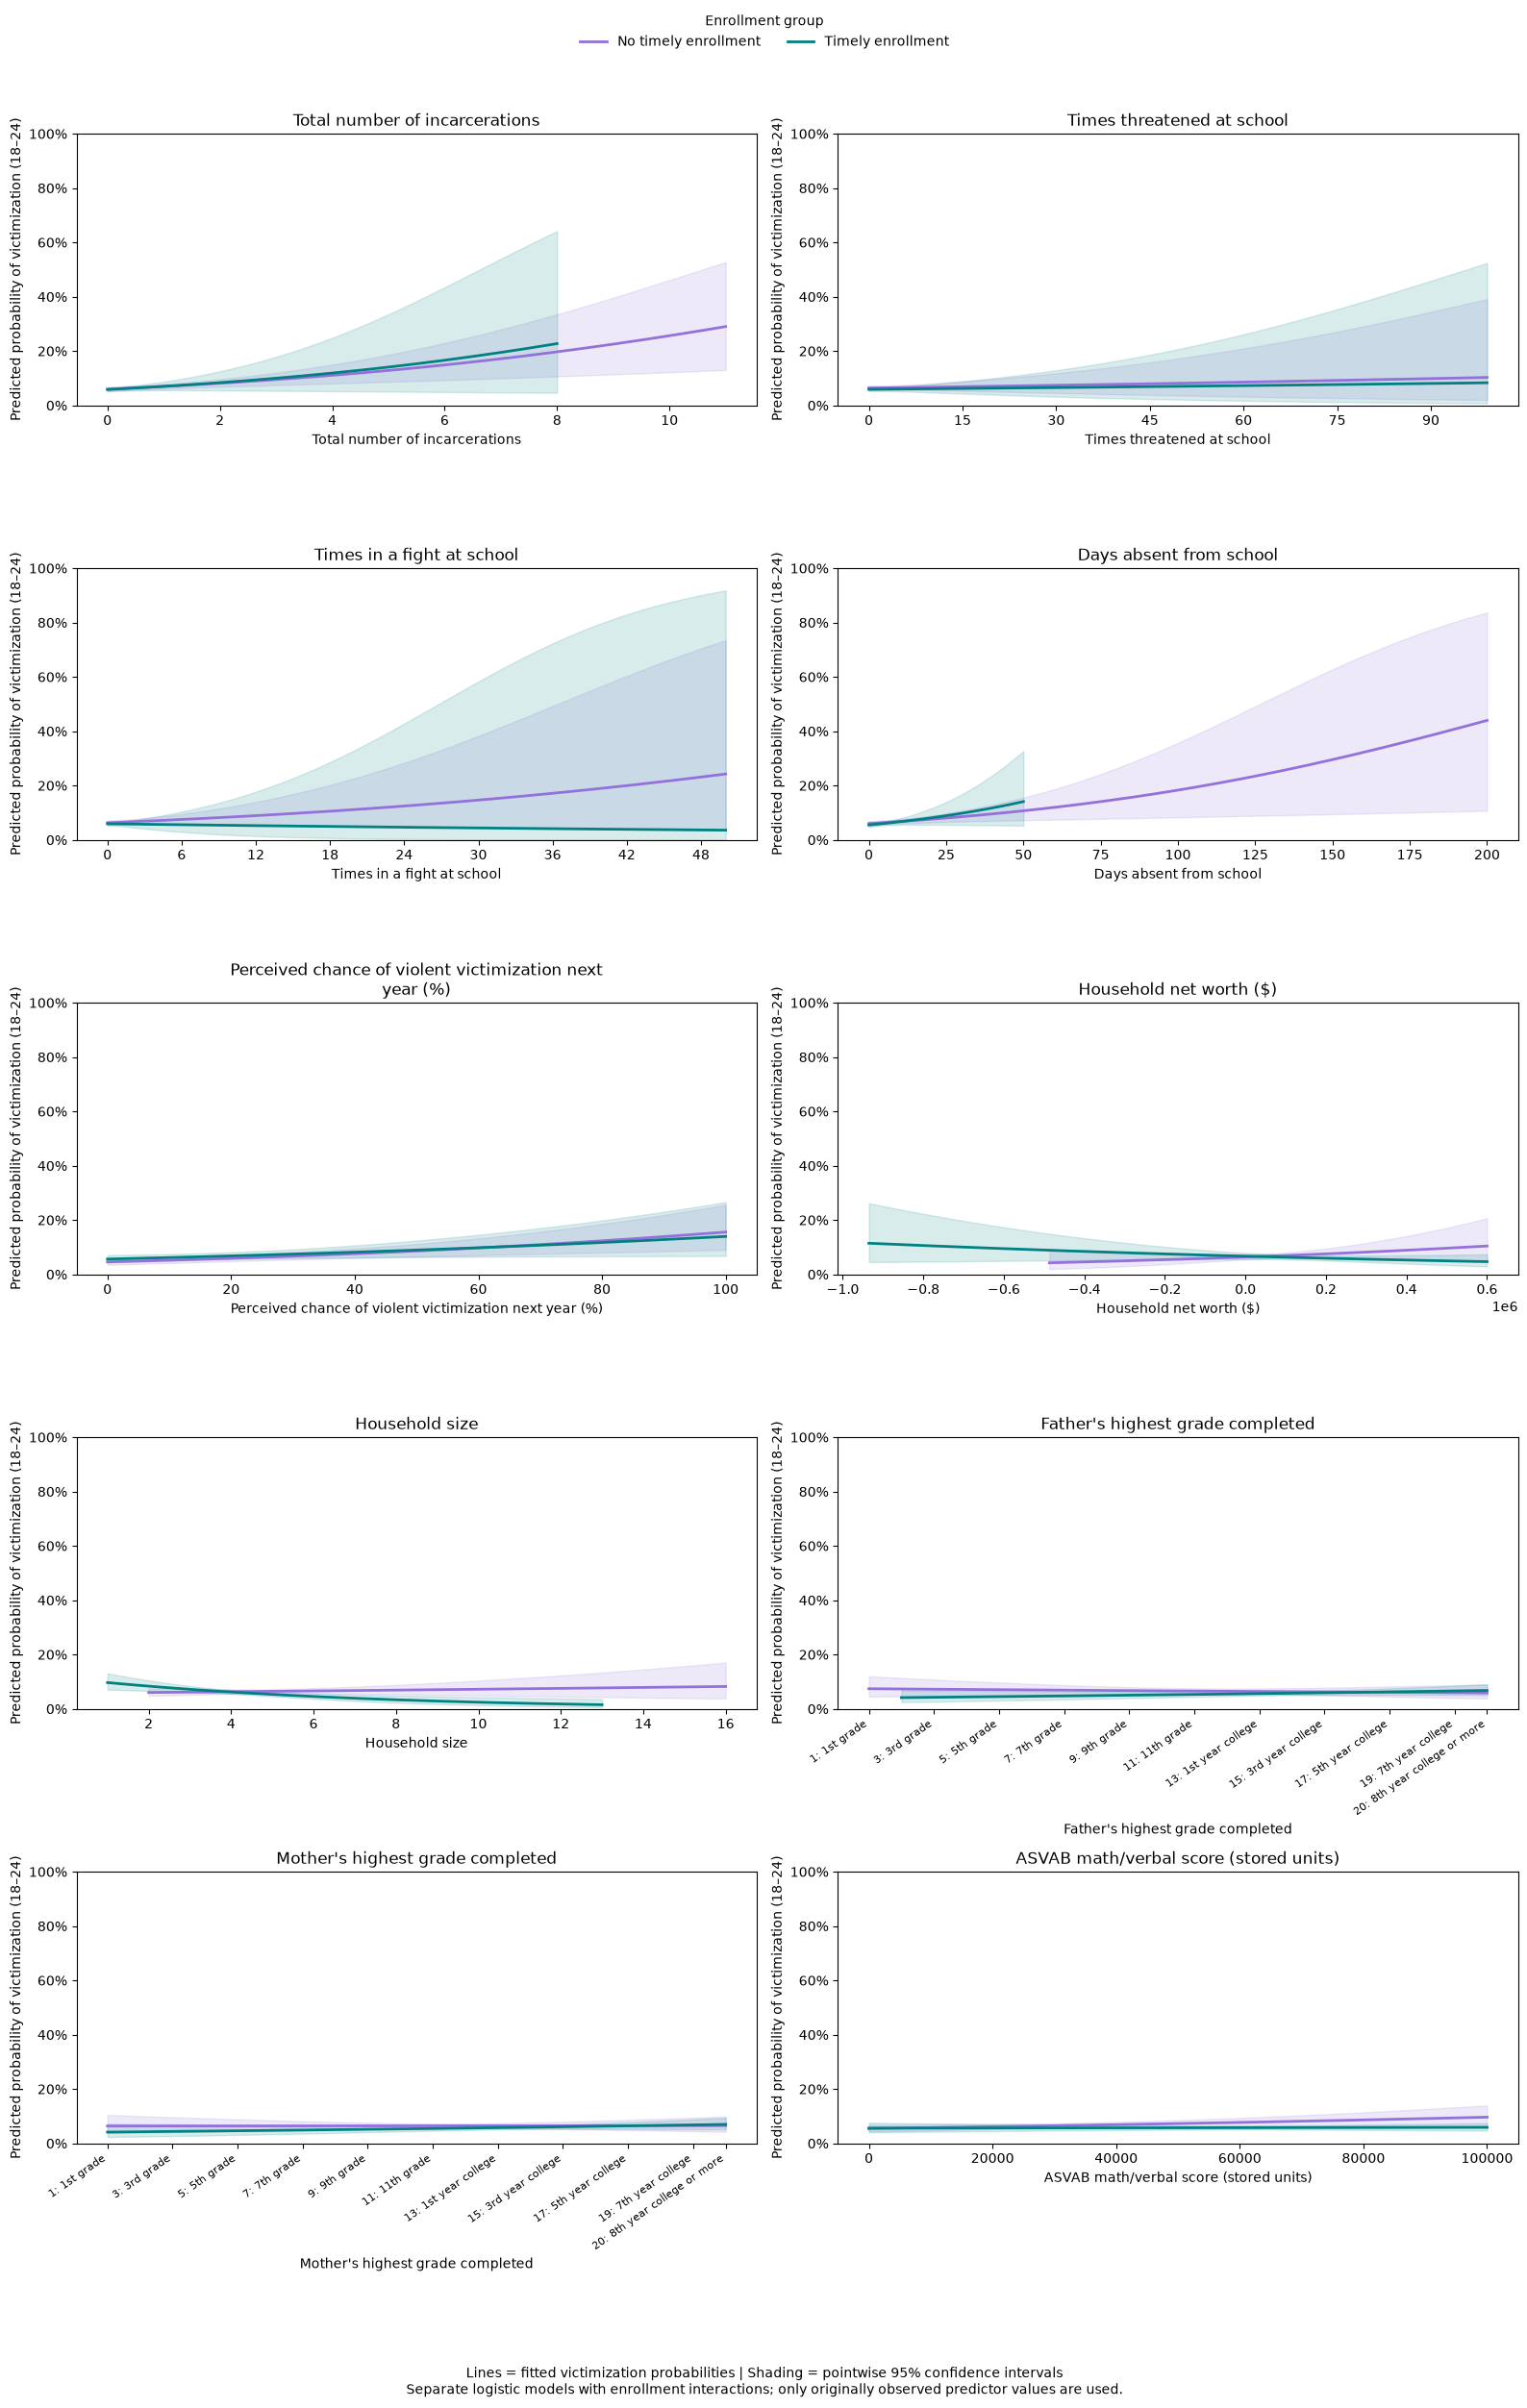

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, PercentFormatter
import textwrap

# Keep your existing DISPLAY_NAMES and education_columns definitions.

groups = ["No timely enrollment", "Timely enrollment"]
colors = {
    "No timely enrollment": "mediumpurple",
    "Timely enrollment": "teal",
}

integer_columns = [
    "total_number_of_incarcerations",
    "r_threatened_to_be_hurt_at_school",
    "r_in_a_fight_at_school",
    "days_r_absent_from_school",
    "household_size",
]

ncols = 2
nrows = (len(continuous) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 5 * nrows),
    squeeze=False,
)

for ax, col in zip(axes.flat, continuous):
    # Exclude median-imputed values.
    plot_df = df.loc[
        df[col + "_missing"] == 0,
        [col, "Y", "enrollment"],
    ].dropna().copy()

    plot_df = plot_df.loc[
        plot_df["enrollment"].isin(groups)
    ].copy()

    name = DISPLAY_NAMES.get(col, col.replace("_", " ").capitalize())

    ax.set(
        xlabel=name,
        ylabel="Predicted probability of victimization (18–24)",
        title=textwrap.fill(name, width=48),
    )
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_ylim(0, 1)

    # Both outcome categories and enrollment groups are needed.
    if (
        plot_df["Y"].nunique() < 2
        or plot_df["enrollment"].nunique() < 2
        or plot_df[col].nunique() < 2
    ):
        ax.text(
            0.5, 0.5, "Insufficient variation to fit model",
            transform=ax.transAxes, ha="center",
        )
        continue

    # Standardize internally for numerical stability.
    # The plotted x-axis remains in the original units.
    center = plot_df[col].mean()
    scale = plot_df[col].std()
    plot_df["score_z"] = (plot_df[col] - center) / scale

    # Interaction allows different slopes by enrollment group.
    model = smf.glm(
        "Y ~ score_z * C(enrollment)",
        data=plot_df,
        family=sm.families.Binomial(),
    ).fit()

    for group in groups:
        observed = plot_df.loc[
            plot_df["enrollment"] == group, col
        ]

        # Restrict each curve to that group's observed range.
        x_grid = np.linspace(observed.min(), observed.max(), 200)

        prediction_df = pd.DataFrame({
            "score_z": (x_grid - center) / scale,
            "enrollment": group,
        })

        predictions = model.get_prediction(
            prediction_df
        ).summary_frame()

        ax.plot(
            x_grid,
            predictions["mean"].to_numpy(),
            color=colors[group],
            linewidth=2,
        )
        ax.fill_between(
            x_grid,
            predictions["mean_ci_lower"].to_numpy(),
            predictions["mean_ci_upper"].to_numpy(),
            color=colors[group],
            alpha=0.15,
        )

    # Education labels now belong on the x-axis.
    if col in education_columns:
        lowest = max(0, int(np.floor(plot_df[col].min())))
        highest = min(20, int(np.ceil(plot_df[col].max())))

        ticks = list(range(lowest, highest + 1, 2))
        if highest not in ticks:
            ticks.append(highest)

        ax.set_xticks(ticks)
        ax.set_xticklabels([
            f"{grade}: {PARENT_EDU.get(grade, str(grade))}"
            for grade in ticks
        ], fontsize=8, rotation=35, ha="right")

    elif col in integer_columns:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

for ax in list(axes.flat)[len(continuous):]:
    ax.set_visible(False)

handles = [
    Line2D([0], [0], color=colors[group], lw=2, label=group)
    for group in groups
]

fig.legend(
    handles=handles,
    title="Enrollment group",
    loc="upper center",
    bbox_to_anchor=(0.5, 1),
    ncol=2,
    frameon=False,
)

fig.text(
    0.5, 0.005,
    "Lines = fitted victimization probabilities | "
    "Shading = pointwise 95% confidence intervals\n"
    "Separate logistic models with enrollment interactions; "
    "only originally observed predictor values are used.",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

####Take-aways to write down
1. Timely enrollees look different on many covariates (higher test scores, more family wealth, fewer prior arrests...). So the raw −0.5 pp gap cannot be read as an effect of college.
2. Some variables are mostly "not asked" (`-4`). They are kept as their own category so those people. stay in the analysis.
3. Many cells have small n; do not over-read individual bars.

### The three key assumptions:

1) **Unconfoundedness:** After accounting for the measured pretreatment characteristics X (covariates), the treatment groups are comparable in the outcomes they would have had under either choice.
$$
(Y^1, Y^0) \perp Z \mid X
$$
2) **Positivity or overlap:** For every relevant profile of covariates, there must be some change of receiving treatment and some chance of not receiving it. AKA if certain students always receive services, there's no similar untreated group to compare them with (must be overlap in propensity score plot)
3) **Consistency:** The outcome we actually observe for someone matches the outcome they would have had under the treatment if they actually received it. The treatment must be defined clearly enough that "treated" means a meaningful, comparable thing. If enrolling at different ages, attending different kinds of colleges, or receiving VERY different campus experiences could affect victimization differently, those may be meaningful different versions of the treatment.

## Outcome Model and Propensity Score Model

#### Causal inference overview
* **Treatment (Z)**: timely college enrollment (1) or not (0).
* **Outcome (Y)**: violently victimized between 18 and 24 (and before enrollment)(1) or not (0).
* **Goal**: the *average treatment effect* (ATE) = (average victimization risk if **everyone** enrolled on time) − (average risk if **no one** did).
* We only see each person under one of the two situations, so we have to *estimate* the other one.
* The two groups differ in background (**confounders**), so we adjust for covariates X.
* This only works if X contains the important confounders (**unconfoundedness**; we cannot test this) and everyone has some chance of both treatments (**positivity**; we can check this).

#### Two models:
1. **Outcome model**: predicts victimization from X, given college entry status and characteristics. **Fit** it separately in each group, then predict *both* scenarios for *everyone*.
**Predicts:** $$E[Y\mid Z,X]$$
 * chance of victimization if they timely enrolled $$\hat Y(1) = mu1$$
 * chance of victimization if they did not timely enrolled $$\hat Y(0) = mu0$$
2. **Propensity score model**: predicts the probability someone timely enrolls in college, given their pre-college characteristics $$e(X)=P(Z=1\mid X)$$

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, brier_score_loss, log_loss, average_precision_score,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             balanced_accuracy_score, f1_score, precision_score, recall_score)
from xgboost import XGBClassifier

ungraded_flags = [
    "biological_father_education_ungraded",
    "biological_mother_education_ungraded",
]
flags = continuous_flags + ungraded_flags

X = df[categorical + continuous + flags]  # the covariates (the information we adjust for)
Y = df["Y"]                                          # outcome column
Z = df["timely_college"]                             # treatment column
print("Rows:", len(df), "| Treated:", Z.sum(), "| Not treated:", (1 - Z).sum())   # quick check of sizes

Rows: 8467 | Treated: 4453 | Not treated: 4014


In [19]:
def make_model(name):

    # for the gam standardize and create splines
    if name == "gam":   # spline basis for each numeric column -> logistic regression = a GAM
        nums = make_pipeline(StandardScaler(), # center each numeric feature and scale to unit variance
                             SplineTransformer(n_knots=5, degree=3)) # cubic splines, 5 locations along the predictor's range to construct spline
    else:
        nums = StandardScaler() # for other, standardize continuous
    prep = ColumnTransformer([
        ("cats",  OneHotEncoder(handle_unknown="ignore"), categorical),
        ("nums",  nums, continuous), # only continous variables get splines
        ("flags", "passthrough", flags),
    ])
    clf = {
        "logistic":      LogisticRegression(max_iter=5000),
        "lasso":         LogisticRegression(penalty="l1", solver="liblinear", C=0.1), # handle overfitting by shinking less important feature coefficients # L1 cna set coefficeints exactly to 0 (shrink coefficients toward zero) # smaller C means stronger regularization (more shrinkage)
        "gam":           LogisticRegression(C=0.1, max_iter=5000),    # C<1: mild ridge penalty keeps curves smooth
        "random_forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=20, n_jobs=-1, random_state=0), # average predictions from 500 randomized decision treees
        "xgboost":       XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
                                       colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1, random_state=0),
    }[name]
    return make_pipeline(prep, clf)

model_names = ["logistic", "lasso", "gam", "random_forest", "xgboost"]
# shuffle observations before making fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0) # divides into 5 groups while keeping the proportion of 0s and 1s approximately the same in each group 
# stratification preserves the original class imbalance (no 50/50 split)

In [20]:
def oof_predict(name, X, y):
    """Out-of-fold predicted probabilities for one model."""
    # request probabilities instead of class lavels
    return cross_val_predict(make_model(name), X, y, cv=cv, method="predict_proba")[:, 1] # uses 4 folds to train data and remaining fold for prediction
    # predict_proba returns 2 columns: P(label=0) and P(label=1)


def metrics_table(y, preds, threshold):
    """One row of metrics per model. `threshold` turns probabilities into 0/1 labels (for the last 4 columns)."""
    rows = {}
    for name, p in preds.items():
        yhat = (p >= threshold).astype(int)
        rows[name] = {"Brier": brier_score_loss(y, p), "LogLoss": log_loss(y, p),
                      "AUC": roc_auc_score(y, p), "F1": f1_score(y, yhat),
                      "Precision": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat)}
    return pd.DataFrame(rows).T

def metric_plots(y, preds, title):
    """Calibration, ROC, precision-recall in one row."""
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    for name, p in preds.items():
        frac, mean_p = calibration_curve(y, p, n_bins=10, strategy="quantile")   # 10 equal-sized risk groups
        ax[0].plot(mean_p, frac, marker="o", label=name)
        fpr, tpr, _ = roc_curve(y, p);              ax[1].plot(fpr, tpr, label=name)
        prec, rec, _ = precision_recall_curve(y, p); ax[2].plot(rec, prec, label=name)
    lim = max(ax[0].get_xlim()[1], ax[0].get_ylim()[1])
    ax[0].plot([0, lim], [0, lim], "k--", lw=1)     # perfect calibration
    ax[1].plot([0, 1], [0, 1], "k--", lw=1)         # coin flip
    ax[2].axhline(y.mean(), color="k", ls="--", lw=1)   # no-skill = base rate
    ax[0].set(title="Calibration (closer to dashed = better)", xlabel="Mean predicted probability", ylabel="Observed fraction")
    ax[1].set(title="ROC", xlabel="False positive rate", ylabel="True positive rate")
    ax[2].set(title="Precision-recall", xlabel="Recall", ylabel="Precision")
    ax[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()

def confusion_tables(y, preds, threshold):
    for name, p in preds.items():
        tn, fp, fn, tp = confusion_matrix(y, (p >= threshold).astype(int)).ravel()
        print(f"{name:14s} TN={tn:5d}  FP={fp:5d}  FN={fn:5d}  TP={tp:5d}")
        # TN = actual 0, predicted 0.
        # FP = actual 0, predicted 1.
        # FN = actual 1, predicted 0.
        # TP = actual 1, predicted 1.

#### Metrics

1. Brier - average sq error of predicted probabilities (lower is better)
2. LogLoss - probability error, strongly penalizing confident wrong predictions (lower is better)
3. AUC - ability to rank positives above negatives (higher is better) 
    - 0.60 means randomly chosen positive gets a higher score than a randomly chosen negative about 60% of the time, counting ties as half
4. AvgPrecision - Summary of precision across recall levels (weighted summary or P-R curve)(higher is better)
    - useful when positives are rare
5. BalancedAcc - average of sensitivity and specificity. Gives pos and neg classes equal importance despite unequal class size
6. F1 - rewards finding positives while limiting false alarms (ignores true negative) (higher is better)
7. Precision - "of everyone flagged, how many actually had the outcome?" (higher is better)
8. Recall - "of everyone who had the outcome, how many did we catch?" (hgiher is better)

#### Confusion Counts
1. TN - no, predicted no
2. FP - no, predicted yes (precision)
3. FN - yes, predicted no (recall)
4. TP - yes, predicted yes (precision)(recall)

precision = TP / TP + FP
recall = TP / TP + FN

#### Plots

1. Calibration Plot - above diagonal -> underpredicts, below diagonal -> overpredicts
2. ROC plot - want curve toward upper left corner (many true positives with few false negatives) (diagonal = change-level ranking)
3. Precision-recall plot - want high precision while maintaining useful recall - hug top right corner (catch every positive case with zero false alarms)

outcome threshold ~ 6%
propensity threshold ~ 50%

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio


===== Outcome model, TREATED (timely enrollment): n=4453, victimization rate=0.059 =====
               Brier  LogLoss    AUC     F1  Precision  Recall
logistic       0.056    0.227  0.581  0.130      0.076   0.452
lasso          0.055    0.223  0.571  0.126      0.071   0.551
gam            0.055    0.223  0.587  0.131      0.076   0.479
random_forest  0.055    0.221  0.591  0.138      0.078   0.570
xgboost        0.056    0.227  0.581  0.130      0.077   0.441
logistic       TN= 2737  FP= 1453  FN=  144  TP=  119
lasso          TN= 2297  FP= 1893  FN=  118  TP=  145
gam            TN= 2650  FP= 1540  FN=  137  TP=  126
random_forest  TN= 2422  FP= 1768  FN=  113  TP=  150
xgboost        TN= 2791  FP= 1399  FN=  147  TP=  116


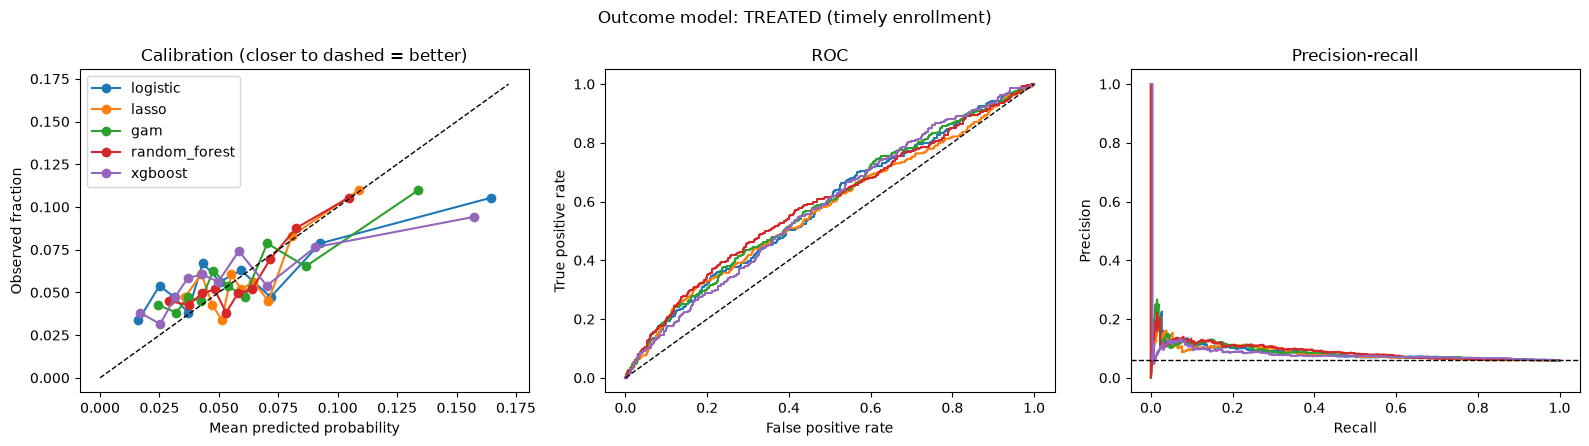


===== Outcome model, UNTREATED: n=4014, victimization rate=0.064 =====
               Brier  LogLoss    AUC     F1  Precision  Recall
logistic       0.061    0.240  0.590  0.134      0.079   0.444
lasso          0.059    0.234  0.605  0.145      0.083   0.580
gam            0.060    0.236  0.589  0.140      0.082   0.490
random_forest  0.059    0.234  0.608  0.152      0.087   0.630
xgboost        0.060    0.240  0.584  0.130      0.077   0.424
logistic       TN= 2423  FP= 1334  FN=  143  TP=  114
lasso          TN= 2113  FP= 1644  FN=  108  TP=  149
gam            TN= 2345  FP= 1412  FN=  131  TP=  126
random_forest  TN= 2051  FP= 1706  FN=   95  TP=  162
xgboost        TN= 2452  FP= 1305  FN=  148  TP=  109


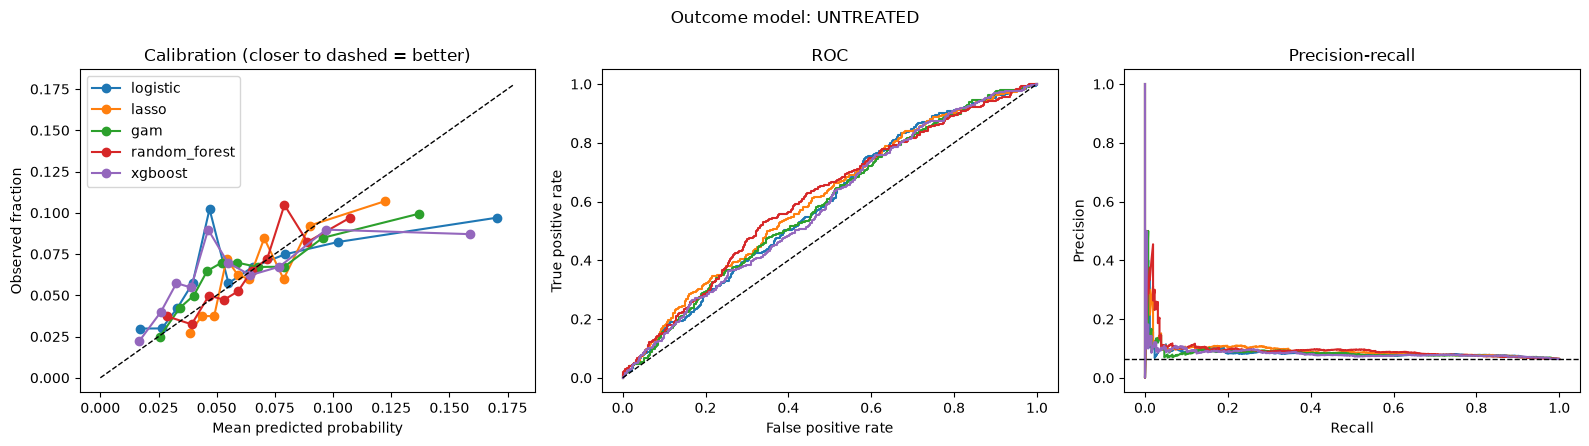

In [21]:
outcome_oof = {0: {}, 1: {}}            # out-of-fold predictions: outcome_oof[arm][model]
# 0 is trained on people who didn't timely entroll, 1 is trained on people who did timely enroll
for arm in [0, 1]:
    # process untreated people, then treated people
    Xa, ya = X[Z == arm], Y[Z == arm]
    # select features and outcomes for people in this treatment group
    for name in model_names:
        # for each of 5 models, generate held out vicitimization probabilities within this group
        outcome_oof[arm][name] = oof_predict(name, Xa, ya)

outcome_tables = {}
for arm, label in [(1, "TREATED (timely enrollment)"), (0, "UNTREATED")]:
    ya = Y[Z == arm].values # actual outcomes (y)
    print(f"\n===== Outcome model, {label}: n={len(ya)}, victimization rate={ya.mean():.3f} =====")
    outcome_tables[arm] = metrics_table(ya, outcome_oof[arm], threshold=ya.mean()) # threshold set to the groups obcerved victimization rate
    print(outcome_tables[arm].round(3).to_string())
    confusion_tables(ya, outcome_oof[arm], threshold=ya.mean())
    metric_plots(ya, outcome_oof[arm], f"Outcome model: {label}")

P-R Plot: The model catches about half the victimization cases, but only about 8 out of every 100 people flagged are actual cases

#### Propensity Score Model

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio

===== Propensity model metrics (out-of-fold) =====
               Brier  LogLoss    AUC     F1  Precision  Recall
logistic       0.166    0.500  0.835  0.768      0.766   0.770
lasso          0.166    0.500  0.835  0.766      0.766   0.766
gam            0.163    0.494  0.840  0.773      0.774   0.771
random_forest  0.171    0.516  0.836  0.766      0.773   0.759
xgboost        0.162    0.489  0.843  0.772      0.770   0.773
logistic       TN= 2968  FP= 1046  FN= 1023  TP= 3430
lasso          TN= 2969  FP= 1045  FN= 1040  TP= 3413
gam            TN= 3011  FP= 1003  FN= 1019  TP= 3434
random_forest  TN= 3020  FP=  994  FN= 1072  TP= 3381
xgboost        TN= 2987  FP= 1027  FN= 1010  TP= 3443


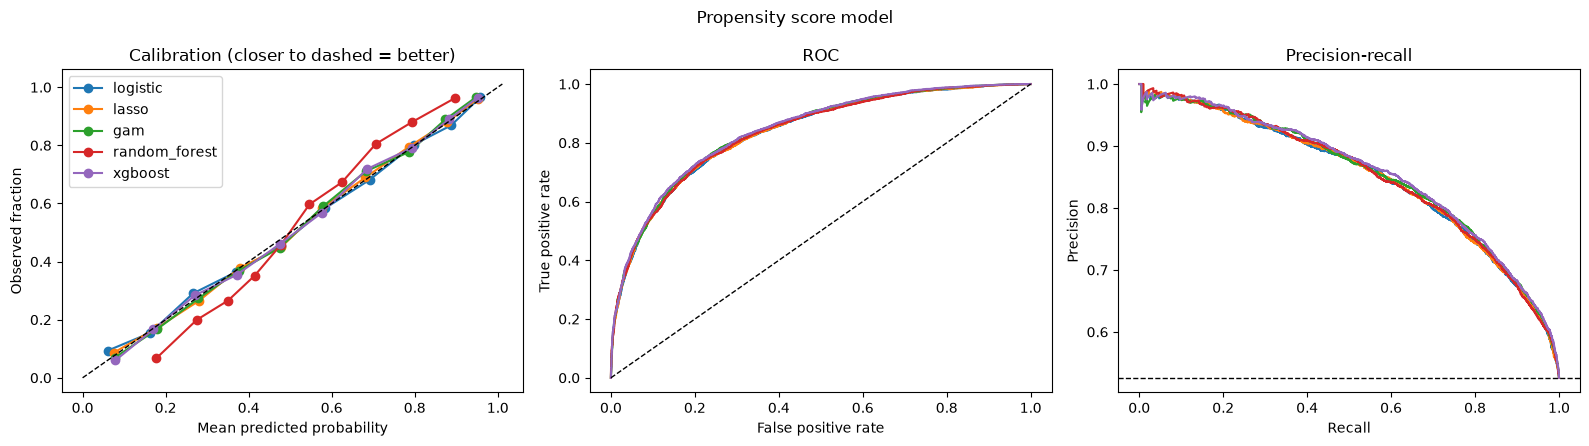

In [22]:
ps_oof = {name: oof_predict(name, X, Z) for name in model_names}
# For each model, predict treatment Z using X across the full sample.
# These are estimated propensity scores: P(Z=1 | X).

zv = Z.values # Convert treatment labels into a NumPy array.

print("===== Propensity model metrics (out-of-fold) =====")
ps_table = metrics_table(zv, ps_oof, threshold=0.5)
print(ps_table.round(3).to_string())
confusion_tables(zv, ps_oof, threshold=0.5)
metric_plots(zv, ps_oof, "Propensity score model")

Propensity scores for ALL models

For each model we fit, using 5-fold **cross-fitting** (each person is predicted by models that never saw them):
* `e`   = propensity score P(enroll on time | X)
* `mu1` = predicted victimization risk if enrolled on time (outcome model fit on treated only)
* `mu0` = predicted victimization risk if not (outcome model fit on untreated only)


In [23]:
def cross_fit_data(name, Xdata, y, z, n_splits=5, seed=0):
    """Return cross-fitted propensity and outcome predictions for these data."""
    # Convert to arrays so train/test indices are used as row positions.
    y = np.asarray(y, dtype=float).ravel()
    z = np.asarray(z, dtype=int).ravel()

    e = np.zeros(len(y))
    mu1 = np.zeros(len(y))
    mu0 = np.zeros(len(y))

    # Stratify folds by the four treatment/outcome combinations.
    folds = StratifiedKFold(
        n_splits=n_splits, shuffle=True, random_state=seed
    )

    for train, test in folds.split(Xdata, 2 * z + y):
        Xtr, Xte = Xdata.iloc[train], Xdata.iloc[test]
        ytr, ztr = y[train], z[train]

        # Estimate enrollment probability for held-out people.
        e[test] = (
            make_model(name).fit(Xtr, ztr).predict_proba(Xte)[:, 1]
        )

        # Predict held-out victimization risk if enrolled.
        treated = ztr == 1
        mu1[test] = (
            make_model(name)
            .fit(Xtr.iloc[treated], ytr[treated])
            .predict_proba(Xte)[:, 1]
        )

        # Predict held-out victimization risk if not enrolled.
        untreated = ztr == 0
        mu0[test] = (
            make_model(name)
            .fit(Xtr.iloc[untreated], ytr[untreated])
            .predict_proba(Xte)[:, 1]
        )

    # Apply the same propensity-score clipping rule in every resample.
    e = np.clip(e, 0.01, 0.99)
    return e, mu1, mu0

nuis = {name: cross_fit_data(name, X, Y, Z) for name in model_names}   # {model: (e, mu1, mu0)}

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio

Propensity score overlap (positivity), all models

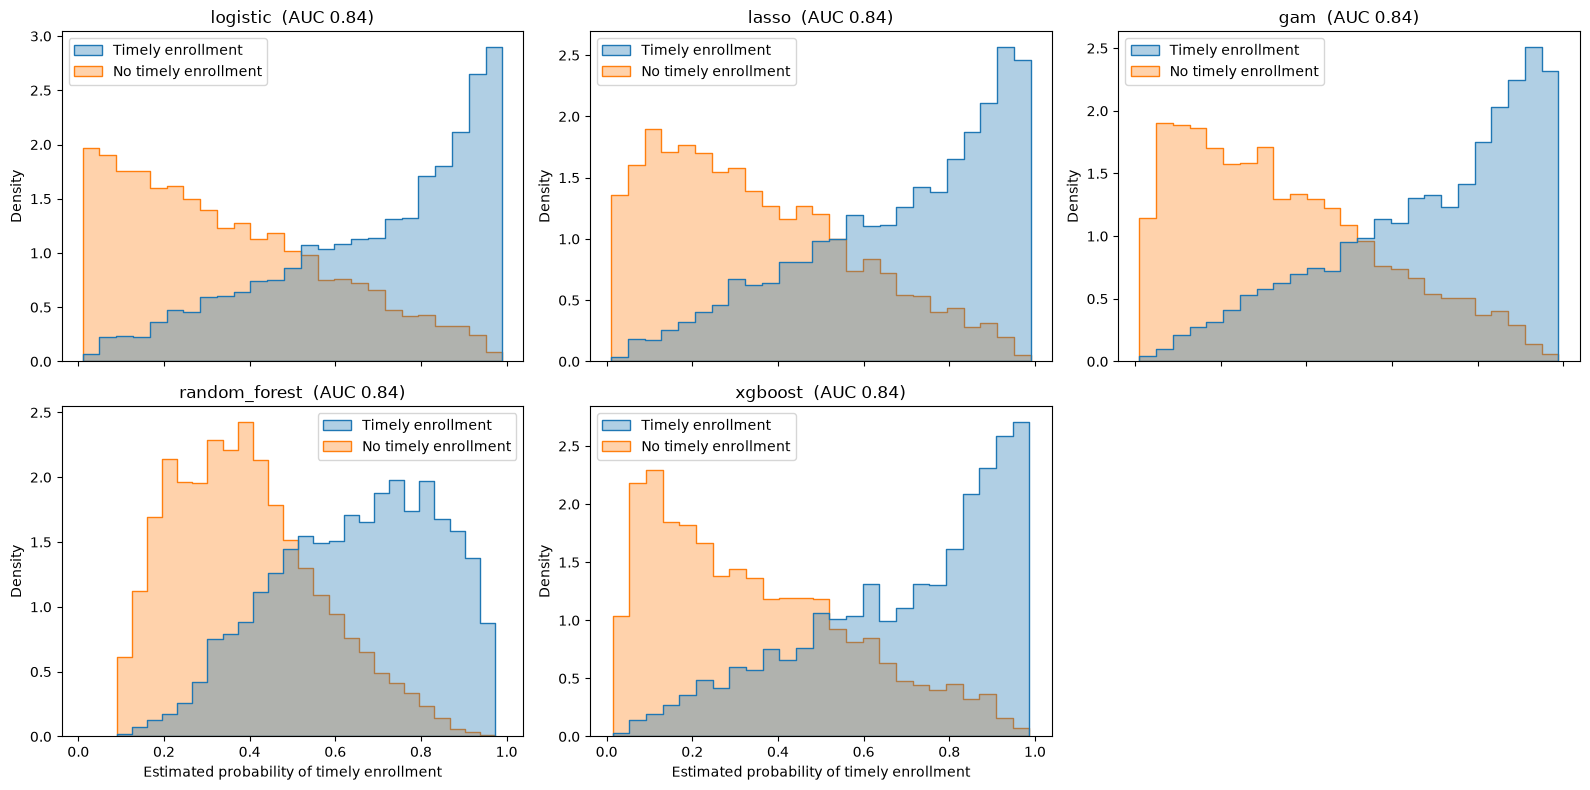

In [24]:
# One histogram per model: propensity scores for treated vs untreated.
# We want the two histograms to overlap; if not, there is nobody comparable.
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for ax, name in zip(axes.flat, model_names):
    e = nuis[name][0]
    sns.histplot(x=e, hue=df["enrollment"].values, bins=25, stat="density",
                 common_norm=False, element="step", alpha=0.35, ax=ax)
    ax.set(title=f"{name}  (AUC {roc_auc_score(Z, e):.2f})", xlabel="Estimated probability of timely enrollment")
axes.flat[-1].set_visible(False)   # 5 models, 6 panels -> hide the empty one
plt.tight_layout(); plt.show()

Covariate balance (Love plot), all models

**IPW** weight = 1/e for treated, 1/(1-e) for untreated. **SMD** = standardized mean difference; |SMD| < 0.1 is well balanced.
Each panel shows the same covariates, before vs after weighting with that model's propensity scores.

Columns with |SMD| > 0.1  (out of 96 )
  before weighting: 45
  after, logistic      : 0
  after, lasso         : 0
  after, gam           : 3
  after, random_forest : 19
  after, xgboost       : 0


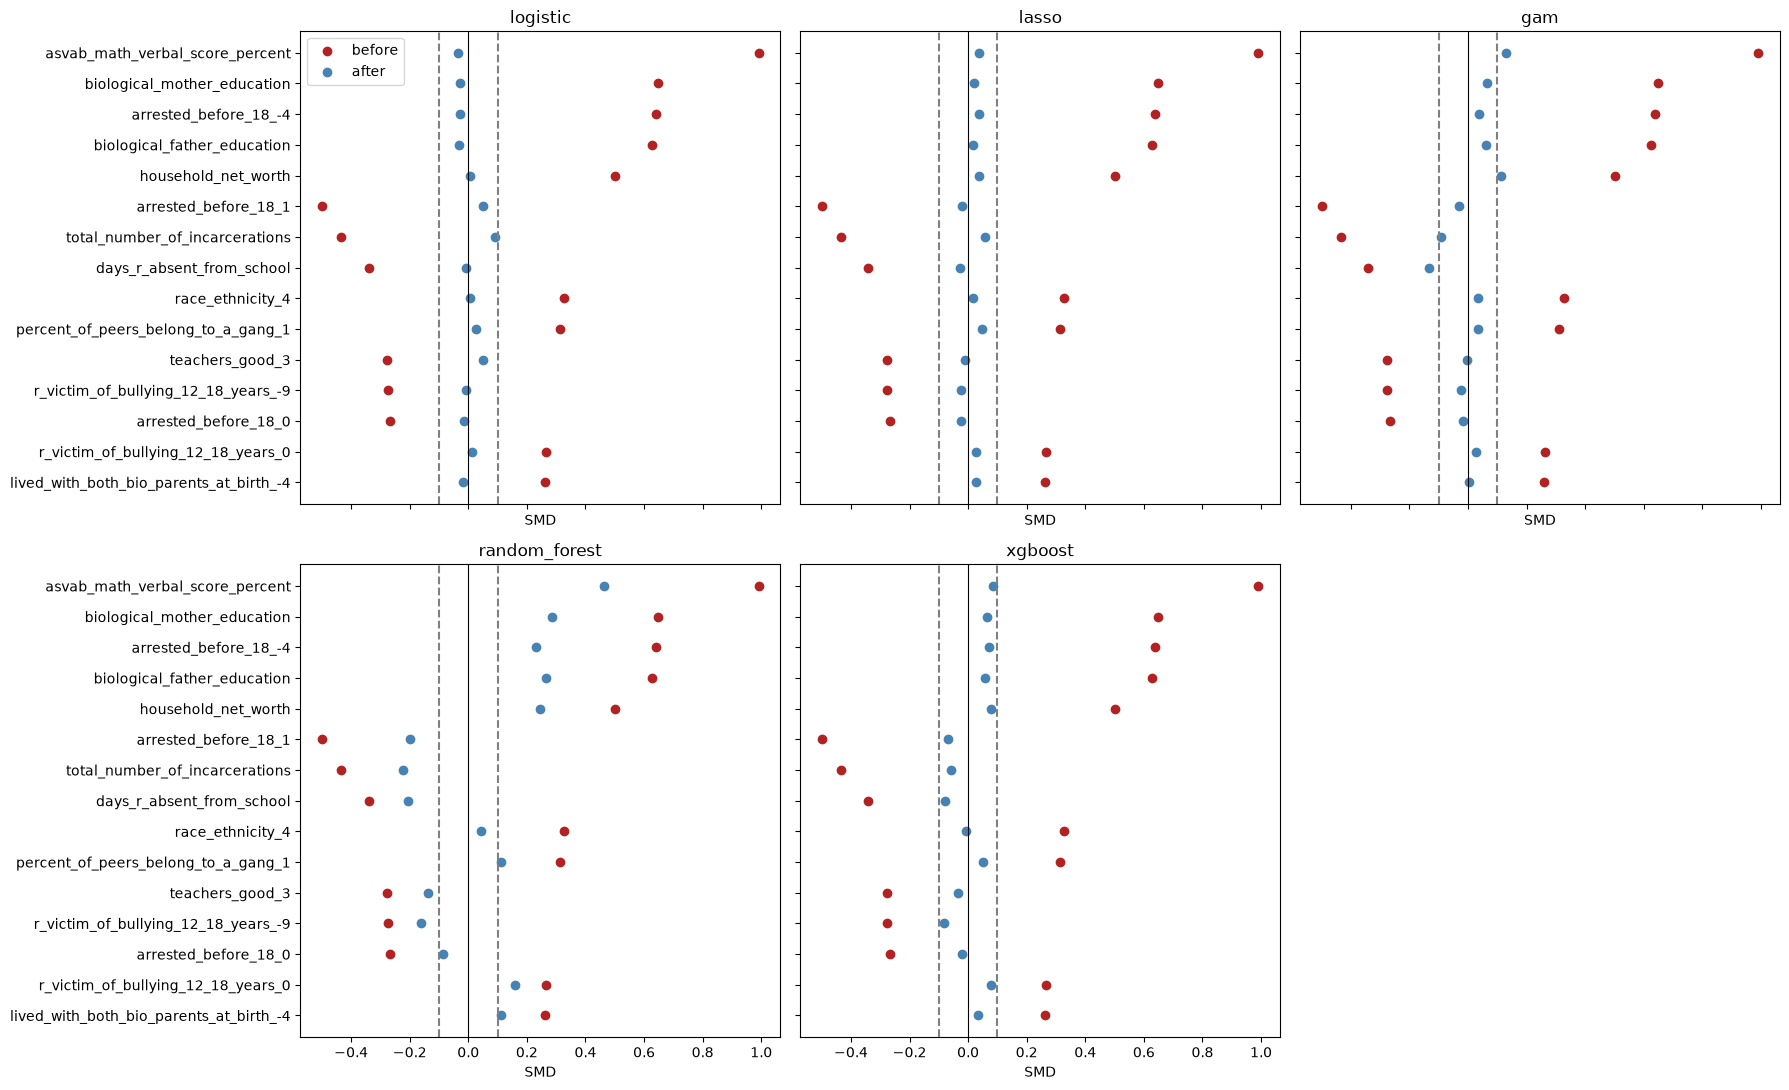

In [25]:
def smd(x, z, w):
    """Weighted standardized mean difference between treated (z=1) and untreated (z=0)."""
    m1 = np.average(x[z == 1], weights=w[z == 1]); m0 = np.average(x[z == 0], weights=w[z == 0])
    v1 = np.average((x[z == 1] - m1) ** 2, weights=w[z == 1]); v0 = np.average((x[z == 0] - m0) ** 2, weights=w[z == 0])
    return (m1 - m0) / np.sqrt((v1 + v0) / 2)

design = pd.concat([pd.get_dummies(df[categorical], dtype=float), df[continuous]], axis=1)  # every covariate as a number
z_arr = Z.values

# SMD before weighting (same for every model)
before = pd.Series({c: smd(design[c].values, z_arr, np.ones(len(df))) for c in design.columns})

# SMD after weighting, one column per model
after = pd.DataFrame(index=design.columns)
for name in model_names:
    e = nuis[name][0]
    w = np.where(z_arr == 1, 1 / e, 1 / (1 - e))
    after[name] = [smd(design[c].values, z_arr, w) for c in design.columns]

# how many covariates are still imbalanced?
print("Columns with |SMD| > 0.1  (out of", len(before), ")")
print("  before weighting:", int((before.abs() > 0.1).sum()))
for name in model_names:
    print(f"  after, {name:14s}:", int((after[name].abs() > 0.1).sum()))

# Love plot: top 15 most imbalanced covariates, one panel per model
top = before.abs().sort_values(ascending=False).head(15).index[::-1]
fig, axes = plt.subplots(2, 3, figsize=(18, 11), sharex=True, sharey=True)
for ax, name in zip(axes.flat, model_names):
    ax.scatter(before[top], top, color="firebrick", label="before")
    ax.scatter(after.loc[top, name], top, color="steelblue", label="after")
    ax.axvline(0, color="black", lw=0.8)
    ax.axvline(-0.1, color="grey", ls="--"); ax.axvline(0.1, color="grey", ls="--")
    ax.set(title=name, xlabel="SMD")
axes.flat[0].legend()
axes.flat[-1].set_visible(False)
plt.tight_layout(); plt.show()

Causal effect estimates: outcome model, IPW, doubly robust

All three estimate the ATE = average risk if everyone enrolled on time − average risk if no one did.

* **Outcome model (g-formula)**: Predict each person's outcome under treatment and under control, then average the predicted differences (average of `mu1 − mu0`). Relies on the outcome model being right.
* **IPW**: weight people by the inverse of their propensity scores to make the treatment groups more comparable. Weight: 1/(probability of the group they are in). Relies on the propensity model being right. This can become unstable when scores are near 0 or 1.
* **Doubly robust (AIPW)**: outcome model + a weighted correction of its errors. Consistent if *either* model is right.

**Bootstrap CI**: resample people with replacement 1,000 times (repeatedly drawing new samples of people, with replacement, from your original dataset), recompute each estimate, and take the 2.5th/97.5th percentiles. If estimates vary a lot from sample to sample, the confidenc interval is wider.
(Simple version: the cross-fitted `e, mu1, mu0` are held fixed rather than refit in every resample, so the CIs mostly capture sampling noise, not model-fitting noise.)

QUESTION: in bootstrapping, e, mu1, and m0 are fixed. So the intervals reflect variation from resampling the observed rows conditional on those fitted predictions. They don't include th euncertainty from refitting the propensity and outcome models. 

In [27]:
def estimates(y, z, e, mu1, mu0):
    """Return three ATE estimates as risk differences (proportions, not percentages)."""
    """
    y: the person’s observed outcome — 1 if they experienced victimization, 0 if not.
    z: the person’s actual enrollment group — 1 for timely enrollment, 0 for no timely enrollment.
    e: the person’s estimated probability of timely enrollment, based on their characteristics. This is the propensity score.
    mu1: the model’s predicted victimization risk for that person if timely enrolled.
    mu0: the model’s predicted victimization risk for that person if not timely enrolled.
    """

    # Outcome-model estimate:
    # For each person, subtract predicted risk (probability victimization) without enrollment (mu0)
    # from predicted risk with enrollment (mu1), then average those differences.
    outcome = np.mean(mu1 - mu0)

    # IPW estimate:
    # For enrolled people (z=1), weight their observed outcome y by 1/e.
    # For non-enrolled people (z=0), weight y by 1/(1-e) and subtract it.
    # Here, e is the estimated probability of timely enrollment for each person.
    ipw = np.mean(z * y / e - (1 - z) * y / (1 - e))

    # Doubly robust estimate:
    # Start with each person's outcome-model risk difference (mu1 - mu0).
    # For enrolled people, add a weighted correction: observed y minus predicted mu1.
    # For non-enrolled people, subtract a weighted correction: observed y minus predicted mu0.
    # The corrections adjust the model estimate using observed outcomes.
    # dr = np.mean(
    #     mu1 - mu0
    #     + z * (y - mu1) / e
    #     - (1 - z) * (y - mu0) / (1 - e)
    # )

    # Return the three estimates in a fixed order:
    # outcome model, IPW, then doubly robust.
    return np.array([outcome, ipw])


# Convert the outcome Y to a numeric NumPy array of floats.
y = Y.values.astype(float)

# Get treatment status Z as a NumPy array: 1 = timely enrollment, 0 = no timely enrollment.
z = Z.values

# Create a random-number generator with a fixed seed.
# The seed makes the same bootstrap samples repeat when you rerun the code.
rng = np.random.default_rng(0)

# Set the number of bootstrap samples to create.
B = 500

# Create 1000 resamples of row indices, each the same size as the original dataset.
# Sampling is with replacement, so a row can appear multiple times or not at all.
# These same resamples will be used for all models and all three estimators.
boot_idx = rng.integers(0, len(y), size=(B, len(y)))

# Create an empty list to collect the final table's rows.
rows = []

# Repeat the estimation and bootstrap process for each outcome-model specification.
for name in model_names:

    # Get this model's nuisance predictions for every person:
    # e = propensity score; mu1 = predicted outcome if enrolled;
    # mu0 = predicted outcome if not enrolled.
    e, mu1, mu0 = nuis[name]

    # Calculate all three estimates using the original, full dataset.
    point = estimates(y, z, e, mu1, mu0)
    
    boots = []

    for b, i in enumerate(boot_idx):
        # Create one bootstrap dataset by sampling rows with replacement.
        Xb = X.iloc[i].reset_index(drop=True)
        yb, zb = y[i], z[i]

        # Refit the cross-fitted nuisance models within this bootstrap sample.
        eb, mu1b, mu0b = cross_fit_data(name, Xb, yb, zb, n_splits=5, seed=b)

        # Store the ATE estimates from this resample.
        boots.append(estimates(yb, zb, eb, mu1b, mu0b))

    boots = np.asarray(boots)

    # For each method, find the 2.5th and 97.5th percentiles of its
    # 1000 bootstrap estimates; these form a 95% percentile interval.
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)

    # Pair each estimate and its interval with the method's readable name.
    for k, method in enumerate(["Outcome model", "IPW"]):

        # Add one result row.
        # Multiply by 100 to express risk differences in percentage points.
        rows.append({
            "model": name,
            "method": method,
            "ATE (pp)": 100 * point[k],
            "CI lower (pp)": 100 * lo[k],
            "CI upper (pp)": 100 * hi[k]
        })

# Turn the collected rows into a pandas DataFrame.
results = pd.DataFrame(rows)

# Print the results rounded to two decimal places, without row numbers.
print(results.round(2).to_string(index=False))

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio

        model        method  ATE (pp)  CI lower (pp)  CI upper (pp)
     logistic Outcome model     -0.02          -1.29           1.33
     logistic           IPW     -0.68          -2.10           1.03
        lasso Outcome model      0.12          -1.05           1.32
        lasso           IPW     -0.27          -1.68           1.10
          gam Outcome model      0.11          -0.99           1.23
          gam           IPW     -0.23          -1.56           0.88
random_forest Outcome model     -0.00          -1.11           1.15
random_forest           IPW     -0.07          -0.90           0.89
      xgboost Outcome model     -0.03          -1.24           1.10
      xgboost           IPW     -0.26          -1.39           0.88


In [31]:
for k, method in enumerate(["Outcome model", "IPW"]):
    rows.append({
        "model": name,
        "method": method,
        "ATE (pp)": 100 * point[k],
        "CI lower (pp)": 100 * lo[k],
        "CI upper (pp)": 100 * hi[k]
    })

# DR confidence interval from the cross-fitted DR scores
e, mu1, mu0 = nuis[name]
e = np.clip(e, 0.01, 0.99)

dr_scores = (
    mu1 - mu0
    + Z * (Y - mu1) / e
    - (1 - Z) * (Y - mu0) / (1 - e)
)

dr_ate = dr_scores.mean()
dr_se = dr_scores.std(ddof=1) / np.sqrt(len(dr_scores))

rows.append({
    "model": name,
    "method": "Doubly robust",
    "ATE (pp)": 100 * dr_ate,
    "CI lower (pp)": 100 * (dr_ate - 1.96 * dr_se),
    "CI upper (pp)": 100 * (dr_ate + 1.96 * dr_se)
})

In [30]:
for name in model_names:
    e, mu1, mu0 = nuis[name]
    e = np.clip(e, 0.01, 0.99)

    dr_scores = (
        mu1 - mu0
        + Z * (Y - mu1) / e
        - (1 - Z) * (Y - mu0) / (1 - e)
    )

    ate = dr_scores.mean()
    se = dr_scores.std(ddof=1) / np.sqrt(len(dr_scores))

    results.append({
        "model": name,
        "method": "Doubly robust",
        "ATE (pp)": 100 * ate,
        "CI lower (pp)": 100 * (ate - 1.96 * se),
        "CI upper (pp)": 100 * (ate + 1.96 * se),
    })

AttributeError: 'DataFrame' object has no attribute 'append'

KeyError: "None of [Index(['logistic', 'lasso', 'gam', 'random_forest', 'xgboost'], dtype='str', name='model')] are in the [index]"

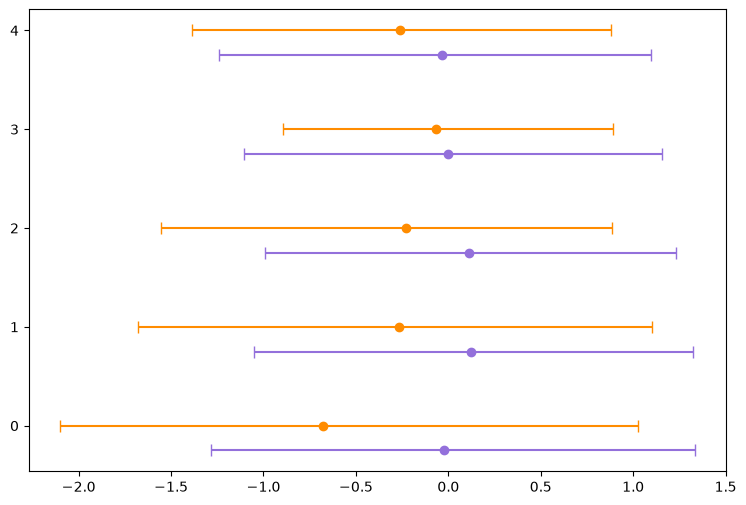

In [ ]:
# Plot: ATE and 95% CI for every model x method. Vertical line at 0 = no effect.
methods = ["Outcome model", "IPW", "Doubly robust"]
colors_m = {"Outcome model": "mediumpurple", "IPW": "darkorange", "Doubly robust": "seagreen"}
fig, ax = plt.subplots(figsize=(9, 6))
for j, method in enumerate(methods):
    r = results[results["method"] == method].set_index("model").loc[model_names]
    ypos = np.arange(len(model_names)) + (j - 1) * 0.25                  # offset each method so they don't overlap
    ax.errorbar(r["ATE (pp)"], ypos,
                xerr=[r["ATE (pp)"] - r["CI lower (pp)"], r["CI upper (pp)"] - r["ATE (pp)"]],
                fmt="o", capsize=4, color=colors_m[method], label=method)
ax.axvline(0, color="black", ls="--", lw=1)
ax.set_yticks(range(len(model_names))); ax.set_yticklabels(model_names)
ax.set(xlabel="ATE on victimization (percentage points)", title="ATE of timely enrollment, 95% bootstrap CI")
ax.legend(); plt.tight_layout(); plt.show()

#### Summary

**Raw victimization vs enrollment**
* raw victimization proportion is slightly lower among timely enrollees (0.5 percentage points)

**covariates vs enrollment (continuous means including median imputed)**
* timely enrollees have, on average, greater family wealth, more parental education, and higher recorded test scores, alongside fewer adverse experiences

**categorical victimization plots**
1. teachers good:
2. discipline is fair:
3. peers who smoke:
4. peers who get drunk:
5. peers belonging to gangs:
6. peers who have had sex:
7. bullying before 12:
8. sex:
9. hard times: 
11. race/ ethnicity:
12. bullying at ages 12-18:
13. mother's prison sentence:
14. father's prison sentence:
15. both biological parents at birth:
16. arrested before 18:

**continuous victimization box plots**
* Timely enrollees generally have higher parental education in both victimization categories.
* Timely enrollees generally have higher ASVAB values in both victimization categories.
* Timely enrollees tend to have higher household net worth.
* Perceived victimization risk is higher among victimized respondents.
* Several count variables have boxes compressed near zero, with long upper tails.

#### TODO

1. missingness in covariates and Y